# Shallow Neural Network with One Hidden Layer
In this notebook, we implement a Shallow Neural Network (SNN) with a single hidden layer (tanh activation in the hidden layer and sigmoid activation in the output layer) to forecast hourly day-ahead electricity prices in Spain.

In [1]:
# Package imports
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from pathlib import Path

# 2 - Load the Dataset and Normalization
We load the engineered master dataset (Master_Dataset_Engineered_2023_2025.xlsx). Data from 2023 and 2024 (17,376 hours) are used as the training set, and data from 2025 (8,760 hours) are used for validation and testing.

In [2]:
# Loading the dataset
input_path = Path("model_input") / "Master_Dataset_Engineered_2023_2025.xlsx"
df = pd.read_excel(input_path)
input_data = df.values  # .values converts the pandas DataFrame to a numpy array

In [3]:
# Categorizing the data into inputs (x) and outputs (y) as well as training set and testing set
train_set_x_orig = input_data[:17376, 2:].astype(float)
train_set_y_orig = input_data[:17376, 1:2].astype(float)

test_set_x_orig  = input_data[17376:, 2:].astype(float)
test_set_y_orig  = input_data[17376:, 1:2].astype(float)

print("train_set_x_orig shape:", train_set_x_orig.shape)
print("train_set_y_orig shape:", train_set_y_orig.shape)
print("test_set_x_orig shape: ", test_set_x_orig.shape)
print("test_set_y_orig shape: ", test_set_y_orig.shape)

train_set_x_orig shape: (17376, 12)
train_set_y_orig shape: (17376, 1)
test_set_x_orig shape:  (8760, 12)
test_set_y_orig shape:  (8760, 1)


In [4]:
# Normalization process
scaler = MinMaxScaler(feature_range=(0, 1))

train_set_x_normalized = scaler.fit_transform(train_set_x_orig)
test_set_x_normalized  = scaler.fit_transform(test_set_x_orig)
train_set_y_normalized = scaler.fit_transform(train_set_y_orig)
test_set_y_normalized  = scaler.fit_transform(test_set_y_orig)

# Transpose the data to put all features in the rows and all samples in the columns
train_set_x_normalized = train_set_x_normalized.T
test_set_x_normalized  = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized  = test_set_y_normalized.T

In [5]:
# Dataset dimensions
m_train = train_set_x_orig.shape[0]
m_test  = test_set_x_orig.shape[0]

print("Number of training examples: m_train = " + str(m_train))
print("Number of testing examples:  m_test  = " + str(m_test))
print("train_set_x shape: " + str(train_set_x_normalized.shape))
print("train_set_y shape: " + str(train_set_y_normalized.shape))
print("test_set_x shape:  " + str(test_set_x_normalized.shape))
print("test_set_y shape:  " + str(test_set_y_normalized.shape))

Number of training examples: m_train = 17376
Number of testing examples:  m_test  = 8760
train_set_x shape: (12, 17376)
train_set_y shape: (1, 17376)
test_set_x shape:  (12, 8760)
test_set_y shape:  (1, 8760)


# 3 - Neural Network Model
We build a Shallow Neural Network with a single hidden layer.

### 3.1 - Defining the neural network structure (layer_sizes)

In [6]:
def layer_sizes(X, Y):

    n_x = X.shape[0]
    n_y = Y.shape[0]
    n_h = 4
    
    return (n_x, n_h, n_y)

### 3.2 - Initialize the model's parameters 

In [7]:
def initialize_parameters(n_x, n_h, n_y):
    
    np.random.seed(2)
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

In [8]:
def sigmoid(z):
    s = 1 / (1 + np.exp(-z))
    return s

### 3.3 - Forward propagation 

In [9]:
def forward_propagation(X, parameters):
   
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    Z1 = np.dot(W1, X) + b1
    A1 = np.tanh(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = sigmoid(Z2)
    
    assert(A2.shape == (1, X.shape[1]))
    
    cache = {"Z1": Z1,
             "A1": A1,
             "Z2": Z2,
             "A2": A2}
    
    return A2, cache

### 3.4 - Compute the cost

In [10]:
def compute_cost(A2, Y):
    
    m = Y.shape[1]  # number of examples
    
    logprobs = (Y * np.log(A2)) + (1 - Y) * np.log(1 - A2)
    cost = -(1 / m) * np.sum(logprobs)
    
    cost = float(np.squeeze(cost))
    
    return cost

### 3.5 - Implement backpropagation 

In [11]:
def backward_propagation(parameters, cache, X, Y):
    
    m = X.shape[1]
    
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    
    A1 = cache["A1"]
    A2 = cache["A2"]
    
    dZ2 = A2 - Y
    dW2 = (1 / m) * np.dot(dZ2, A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = np.dot(W2.T, dZ2) * (1 - np.power(A1, 2))
    dW1 = (1 / m) * np.dot(dZ1, X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)
    
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}
    
    return grads

### 3.6 - Update parameters 

In [12]:
def update_parameters(parameters, grads, learning_rate=0.85):
    
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    dW1 = grads["dW1"]
    db1 = grads["db1"]
    dW2 = grads["dW2"]
    db2 = grads["db2"]
    
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2
    
    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

### 3.7 - Integration 

In [13]:
def nn_model(X, Y, n_h, num_iterations=2000, learning_rate=0.85, print_cost=False):
    
    np.random.seed(3)
    n_x = layer_sizes(X, Y)[0]
    n_y = layer_sizes(X, Y)[2]
    
    parameters = initialize_parameters(n_x, n_h, n_y)
    costs = []
    
    for i in range(0, num_iterations):
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate=learning_rate)
        
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print("Cost after iteration %i: %f" % (i, cost))

    parameters["costs"] = costs
    parameters["learning_rate"] = learning_rate
    parameters["num_iterations"] = num_iterations
    parameters["n_h"] = n_h
    return parameters

# 4 - Predict and Baseline Model Training (12 Features)
### 4.1 - Predict 

In [14]:
def predict(parameters, X):
    
    A2, cache = forward_propagation(X, parameters)
    predictions = A2
    return predictions

### 4.2 - Test the Baseline SNN Model on the Electricity Dataset (All 12 Features)
Following the course tutorial, we first train the Shallow Neural Network with `n_h = 20` hidden units, `learning_rate = 0.85`, and `num_iterations = 2000` using all 12 features.

In [15]:
# Baseline training with n_h = 20 hidden units
n_h = 20
learning_rate = 0.85
num_iterations = 2000

parameters = nn_model(
    train_set_x_normalized,
    train_set_y_normalized,
    n_h=n_h,
    num_iterations=num_iterations,
    learning_rate=learning_rate,
    print_cost=True
)

Y_prediction_train = predict(parameters, train_set_x_normalized)
Train_accuracy = 100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100

Y_prediction_test = predict(parameters, test_set_x_normalized)
Test_accuracy = 100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100

print("Train Accuracy for {} hidden units: {} %".format(n_h, Train_accuracy))
print("Test Accuracy for {} hidden units: {} %".format(n_h, Test_accuracy))

Cost after iteration 0: 0.693170
Cost after iteration 100: 0.569108
Cost after iteration 200: 0.562053
Cost after iteration 300: 0.560403
Cost after iteration 400: 0.559346
Cost after iteration 500: 0.558626
Cost after iteration 600: 0.558151
Cost after iteration 700: 0.557833
Cost after iteration 800: 0.557610
Cost after iteration 900: 0.557443
Cost after iteration 1000: 0.557310
Cost after iteration 1100: 0.557199
Cost after iteration 1200: 0.557103
Cost after iteration 1300: 0.557019
Cost after iteration 1400: 0.556943
Cost after iteration 1500: 0.556874
Cost after iteration 1600: 0.556811
Cost after iteration 1700: 0.556752
Cost after iteration 1800: 0.556698
Cost after iteration 1900: 0.556646
Train Accuracy for 20 hidden units: 93.89132748242518 %
Test Accuracy for 20 hidden units: 94.47039114053885 %


### Cost Function
Plot of the cost function across training iterations.

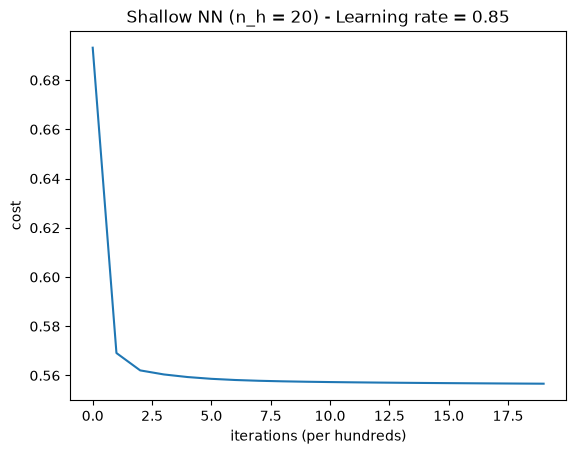

In [16]:
costs = np.squeeze(parameters["costs"])
plt.plot(costs)
plt.ylabel("cost")
plt.xlabel("iterations (per hundreds)")
plt.title("Shallow NN (n_h = 20) - Learning rate = " + str(parameters["learning_rate"]))
plt.show()

### Denormalizing
We reverse the Min-Max normalization to obtain the predicted electricity prices in EUR/MWh and compare them against the observed prices.

In [17]:
# Reverse the normalization to get the original data
Y_prediction_test_real_scale = scaler.inverse_transform(predict(parameters, test_set_x_normalized))

# 6 - Hyperparameter Optimization

The same way we did it in LR, first half of 2025 for tune hyperparameters; second half for evaluation.

### 6.1 - Grid Search

In [18]:
# First half of 2025 for hyperparameter optimization (Validation Set)
X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

# Second half of 2025 for final evaluation (Final Test Set)
X_test_final_norm = test_set_x_normalized[:, 4380:]
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

# Hyperparameter grid for SNN
hidden_layer_list = [4, 10, 20]
learning_rates    = [0.1, 0.5, 0.85, 1.2]
iterations_list   = [500, 1000, 2000]

grid_results = []

for n_h in hidden_layer_list:
    for lr in learning_rates:
        for n_iter in iterations_list:
            params_g = nn_model(
                train_set_x_normalized, train_set_y_normalized,
                n_h=n_h, num_iterations=n_iter, learning_rate=lr, print_cost=False
            )
            
            Y_pred_train = predict(params_g, train_set_x_normalized)
            Y_pred_val   = predict(params_g, X_val_norm)
            
            train_acc = 100 - np.mean(np.abs(Y_pred_train - train_set_y_normalized)) * 100
            val_acc   = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm)) * 100
            
            y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
            val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
            val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))
            
            grid_results.append({
                "Hidden_Units (n_h)": n_h,
                "Learning_Rate": lr,
                "Iterations": n_iter,
                "Final_Cost": round(params_g["costs"][-1], 6),
                "Train_Acc (%)": round(train_acc, 2),
                "Val_Acc (%)": round(val_acc, 2),
                "Val_MAE (EUR/MWh)": round(val_mae, 2),
                "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
            })

df_grid = pd.DataFrame(grid_results)
best_row = df_grid.loc[df_grid["Val_MAE (EUR/MWh)"].idxmin()]

print(df_grid.to_string(index=True))
print("\nBest hyperparameters in validation (Grid Search):")
print(best_row)

    Hidden_Units (n_h)  Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
0                    4           0.10         500    0.640685          84.49        82.76              43.97               49.56
1                    4           0.10        1000    0.569652          92.32        92.70              18.61               24.28
2                    4           0.10        2000    0.561845          93.06        93.77              15.88               21.13
3                    4           0.50         500    0.561651          93.18        93.95              15.44               20.72
4                    4           0.50        1000    0.558572          93.56        94.31              14.51               19.90
5                    4           0.50        2000    0.557049          93.82        94.31              14.51               19.70
6                    4           0.85         500    0.559538          93.49        94.27        

### 6.2 - Randomized Search
Next, we run a Randomized Search of 15 random trials sampling n_h, learning_rate, and num_iterations across the search space.

In [19]:
rng = np.random.RandomState(42)
n_search = 35
random_results = []

for i in range(n_search):
    n_h    = int(rng.choice([4, 6, 8, 10, 12, 16, 20, 24]))
    lr     = round(float(rng.uniform(0.05, 1.2)), 4)
    n_iter = int(rng.choice([500, 800, 1000, 1500, 2000]))
    
    params_r = nn_model(
        train_set_x_normalized, train_set_y_normalized,
        n_h=n_h, num_iterations=n_iter, learning_rate=lr, print_cost=False
    )
    
    Y_pred_train = predict(params_r, train_set_x_normalized)
    Y_pred_val   = predict(params_r, X_val_norm)
    
    train_acc = 100 - np.mean(np.abs(Y_pred_train - train_set_y_normalized)) * 100
    val_acc   = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm)) * 100
    
    y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
    val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
    val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))
    
    random_results.append({
        "Hidden_Units (n_h)": n_h,
        "Learning_Rate": lr,
        "Iterations": n_iter,
        "Final_Cost": round(params_r["costs"][-1], 6),
        "Train_Acc (%)": round(train_acc, 2),
        "Val_Acc (%)": round(val_acc, 2),
        "Val_MAE (EUR/MWh)": round(val_mae, 2),
        "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
    })

df_random = pd.DataFrame(random_results)
best_random_row = df_random.loc[df_random["Val_MAE (EUR/MWh)"].idxmin()]

print(df_random.to_string(index=False))
print("\nBest hyperparameters in validation (Randomized Search):")
print(best_random_row)

 Hidden_Units (n_h)  Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
                 20         0.9660        1000    0.557285          93.78        94.28              14.59               19.65
                 24         0.7385         800    0.559336          93.48        94.25              14.66               19.84
                  8         0.1650        1000    0.563005          92.93        93.58              16.38               21.62
                 24         0.4338        1000    0.560437          93.27        94.09              15.08               20.24
                 16         0.1149        1500    0.562506          92.96        93.63              16.24               21.47
                 16         0.2942        1500    0.559170          93.45        94.24              14.68               19.95
                 12         0.7601         800    0.558584          93.58        94.31              14.50             

### Grid Search vs. Randomized Search Visualization

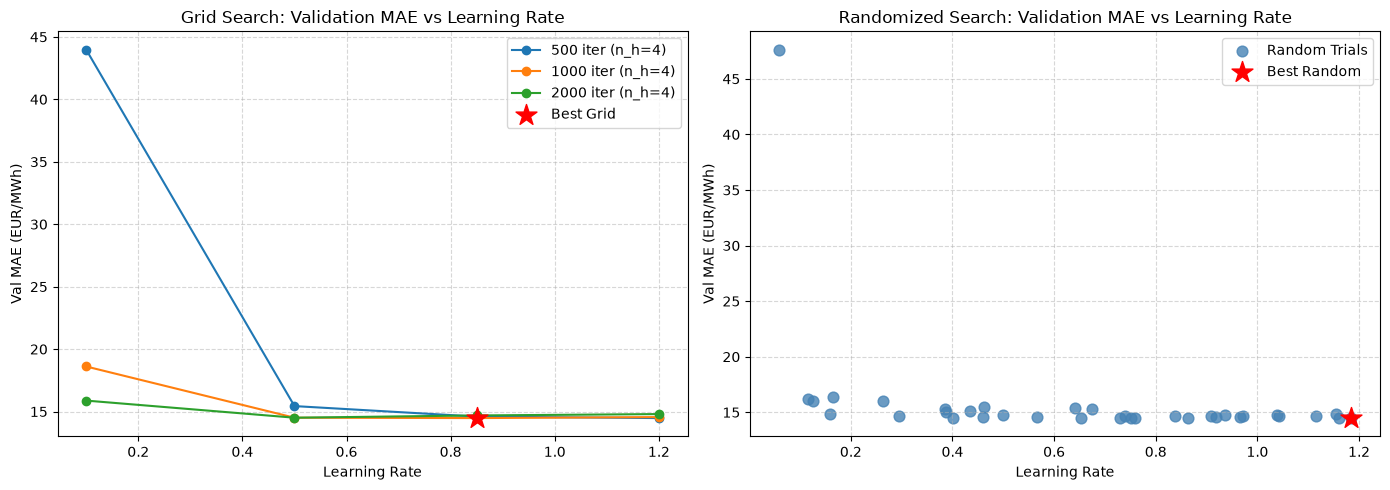

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Grid Search curves for the best hidden layer size
best_nh_grid = int(best_row["Hidden_Units (n_h)"])
df_grid_nh = df_grid[df_grid["Hidden_Units (n_h)"] == best_nh_grid]

for n_iter in iterations_list:
    subset = df_grid_nh[df_grid_nh["Iterations"] == n_iter]
    axes[0].plot(subset["Learning_Rate"], subset["Val_MAE (EUR/MWh)"], marker="o", label=f"{n_iter} iter (n_h={best_nh_grid})")

axes[0].scatter(best_row["Learning_Rate"], best_row["Val_MAE (EUR/MWh)"], color="red", marker="*", s=250, zorder=5, label="Best Grid")
axes[0].set_title("Grid Search: Validation MAE vs Learning Rate")
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Val MAE (EUR/MWh)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(df_random["Learning_Rate"], df_random["Val_MAE (EUR/MWh)"], color="steelblue", s=60, alpha=0.8, label="Random Trials")
axes[1].scatter(best_random_row["Learning_Rate"], best_random_row["Val_MAE (EUR/MWh)"], color="red", marker="*", s=250, zorder=5, label="Best Random")
axes[1].set_title("Randomized Search: Validation MAE vs Learning Rate")
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Val MAE (EUR/MWh)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 6.3 - Evaluation on the Final Test Set (2nd Half of 2025 - 12 Features)
Using the best hyperparameters found in validation, we evaluate our 12-feature Shallow Neural Network on the Final Test Set (2nd half of 2025) and plot the 1-week forecast.

In [21]:
best_nh   = int(best_row["Hidden_Units (n_h)"])
best_lr   = float(best_row["Learning_Rate"])
best_iter = int(best_row["Iterations"])

params_best_12 = nn_model(
    train_set_x_normalized, train_set_y_normalized,
    n_h=best_nh, num_iterations=best_iter, learning_rate=best_lr, print_cost=False
)

Y_pred_test_final = predict(params_best_12, X_test_final_norm)
test_final_acc = 100 - np.mean(np.abs(Y_pred_test_final - Y_test_final_norm)) * 100

y_pred_test_final_eur = scaler.inverse_transform(Y_pred_test_final.T)
test_final_mae  = np.mean(np.abs(y_pred_test_final_eur - y_test_final_orig))
test_final_rmse = np.sqrt(np.mean((y_pred_test_final_eur - y_test_final_orig) ** 2))

print(f"Hyperparameters used -> Hidden Units (n_h): {best_nh} | Learning Rate: {best_lr} | Iterations: {best_iter}")
print(f"Final Test Accuracy: {test_final_acc:.2f} %")
print(f"Final Test MAE:      {test_final_mae:.2f} EUR/MWh")
print(f"Final Test RMSE:     {test_final_rmse:.2f} EUR/MWh")

Hyperparameters used -> Hidden Units (n_h): 4 | Learning Rate: 0.85 | Iterations: 1000
Final Test Accuracy: 94.50 %
Final Test MAE:      14.02 EUR/MWh
Final Test RMSE:     17.55 EUR/MWh


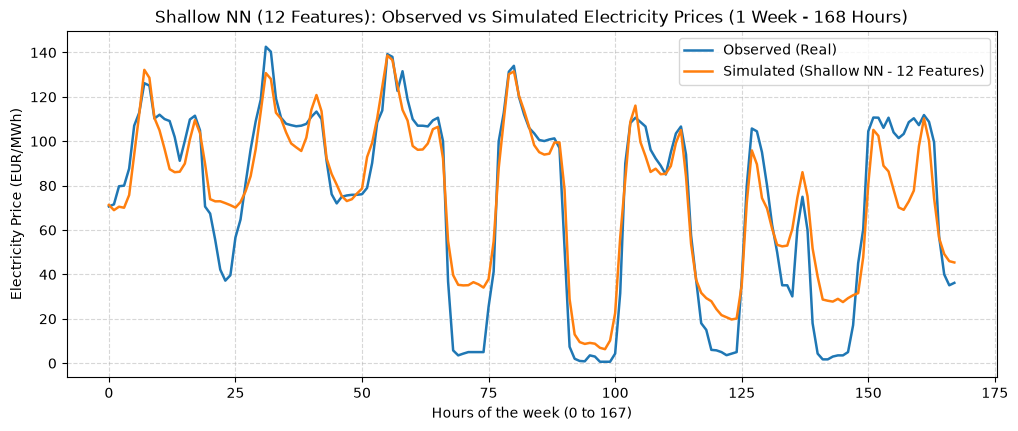

In [22]:
# Observed vs Simulated for 1 Week (168 hours) on the Final Test Set
hours_week = np.arange(0, 168, 1)
y_obs_week  = y_test_final_orig[:168]
y_pred_week = y_pred_test_final_eur[:168]

plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y_obs_week, label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y_pred_week, label="Simulated (Shallow NN - 12 Features)", linewidth=1.8)
plt.title("Shallow NN (12 Features): Observed vs Simulated Electricity Prices (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 7 - Feature importance study
## 7.1 - Feature Importance from first-layer weightts
In a Shallow Neural Network, the importance of each normalized input feature can be measured by the mean absolute weight connecting that input to all hidden neurons. e.g. if you have 4 neurons, each variable will have 4 different weights, so you need to compute the mean (and absolute value due to negative numbers).

              Feature  Mean_Abs_W1
      Wind_Onshore_MW     0.707135
     Load_Forecast_MW     0.451913
           Price_t_24     0.414530
             Solar_MW     0.406032
          Price_t_168     0.301873
Nuclear_Generation_MW     0.298972
  Hydro_Reservoir_MWh     0.172391
           Is_Weekend     0.162047
         Price_24h_MA     0.149715
                Month     0.132375
           Price_t_48     0.097736
                 Hour     0.062252


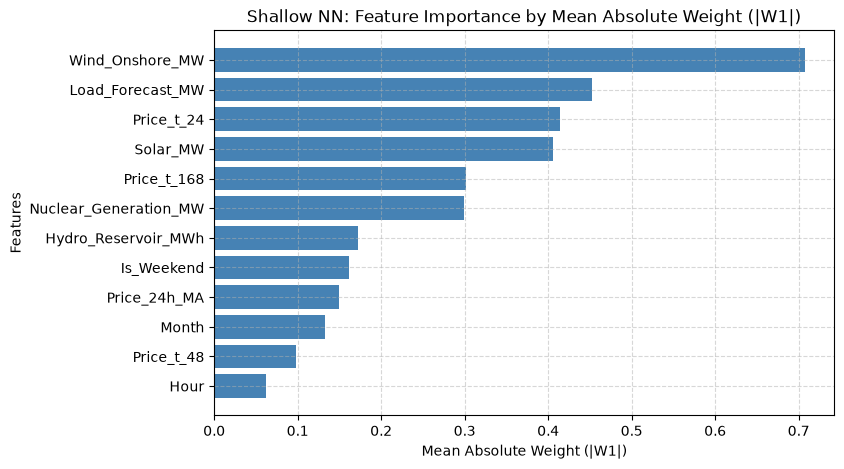

In [23]:
feature_names = df.columns[2:].tolist()

# Compute mean absolute weight across hidden units for each input feature
mean_abs_w1 = np.mean(np.abs(params_best_12["W1"]), axis=0)

importance_snn_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_W1": mean_abs_w1
}).sort_values(by="Mean_Abs_W1", ascending=False)

print(importance_snn_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance_snn_df["Feature"], importance_snn_df["Mean_Abs_W1"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Shallow NN: Feature Importance by Mean Absolute Weight (|W1|)")
plt.xlabel("Mean Absolute Weight (|W1|)")
plt.ylabel("Features")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 7.2 - Retraining the Shallow Neural Network with Selected Features (9 Features)
From the SNN feature importance ranking above, we observe that the 3 features with the lowest weights are:

-Hour (0.062)

-Price_t_48 (0.098)  

-Month (0.132)

Interestingly, this aligns with the findings of Sridhar et al. (2022), who noted that while linear models benefit from including both 24-hour and 48-hour price lags, Artificial Neural Networks perform better without P_t48 because the non-linear hidden layer already captures the temporal dependencies through Price_t_24 and Price_t_168.

Therefore, we remove Price_t_48 (index 6), Hour (index 9), and Month (index 10), keeping the top 9 features, and retrain the Shallow Neural Network using the optimal hyperparameters.

In [24]:
# Keep the top 9 features (removing Price_t_48 [6], Hour [9], and Month [10])
keep_indices = [0, 1, 2, 3, 4, 5, 7, 8, 11]

train_set_x_reduced = train_set_x_normalized[keep_indices, :]
test_set_x_reduced  = test_set_x_normalized[keep_indices, :]

parameters_reduced = nn_model(
    train_set_x_reduced,
    train_set_y_normalized,
    n_h=best_nh,
    num_iterations=best_iter,
    learning_rate=best_lr,
    print_cost=True
)

Y_prediction_train_red = predict(parameters_reduced, train_set_x_reduced)
Train_accuracy_red = (100 - np.mean(np.abs(Y_prediction_train_red - train_set_y_normalized)) * 100)

Y_prediction_test_red = predict(parameters_reduced, test_set_x_reduced)
Test_accuracy_red = (100 - np.mean(np.abs(Y_prediction_test_red - test_set_y_normalized)) * 100)

print("Reduced Model (9 Features) - Train Accuracy: {} %".format(Train_accuracy_red))
print("Reduced Model (9 Features) - Test Accuracy:  {} %".format(Test_accuracy_red))

Cost after iteration 0: 0.693107
Cost after iteration 100: 0.582645
Cost after iteration 200: 0.562208
Cost after iteration 300: 0.560196
Cost after iteration 400: 0.559013
Cost after iteration 500: 0.558266
Cost after iteration 600: 0.557800
Cost after iteration 700: 0.557491
Cost after iteration 800: 0.557271
Cost after iteration 900: 0.557102
Reduced Model (9 Features) - Train Accuracy: 93.80946230660821 %
Reduced Model (9 Features) - Test Accuracy:  94.33117270747586 %


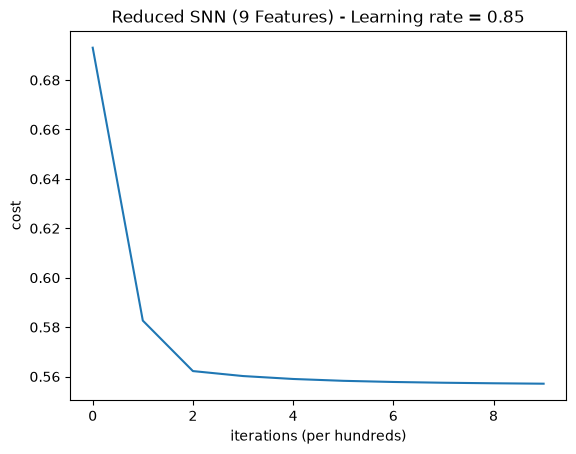

In [25]:
# Cost curve for the Reduced SNN Model (9 Features)
costs_red = np.squeeze(parameters_reduced["costs"])
plt.plot(costs_red)
plt.ylabel("cost")
plt.xlabel("iterations (per hundreds)")
plt.title("Reduced SNN (9 Features) - Learning rate = " + str(parameters_reduced["learning_rate"]))
plt.show()

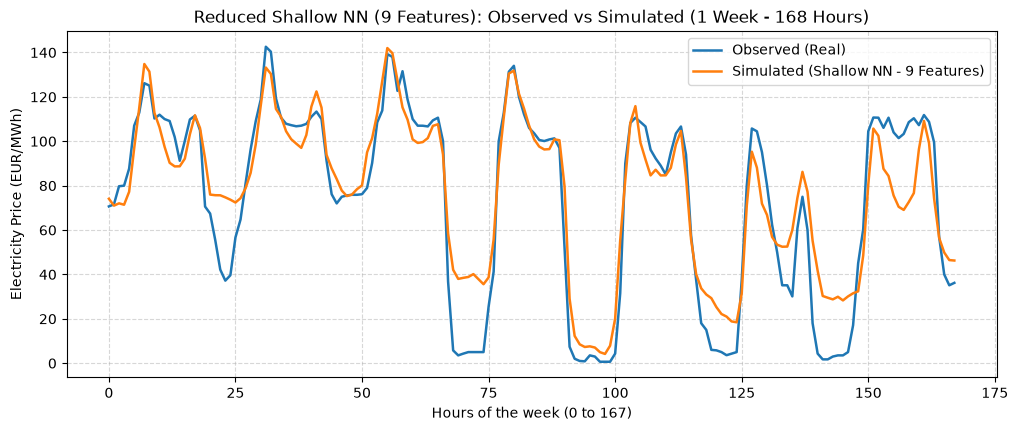

In [ ]:
# Reverse normalization and plot 1 week (first week of July)
X_test_final_reduced = X_test_final_norm[keep_indices, :]
Y_pred_test_final_red = predict(parameters_reduced, X_test_final_reduced)
test_final_red_acc = 100 - np.mean(np.abs(Y_pred_test_final_red - Y_test_final_norm)) * 100

y_pred_test_final_red_eur = scaler.inverse_transform(Y_pred_test_final_red.T)
test_final_red_mae  = np.mean(np.abs(y_pred_test_final_red_eur - y_test_final_orig))
test_final_red_rmse = np.sqrt(np.mean((y_pred_test_final_red_eur - y_test_final_orig) ** 2))

hours_week = np.arange(0, 168, 1)
plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y_test_final_orig[:168], label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y_pred_test_final_red_eur[:168], label="Simulated (Shallow NN - 9 Features)", linewidth=1.8)
plt.title("Reduced Shallow NN (9 Features): Observed vs Simulated (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 7.3 - Final Comparison: Full SNN (12 Features) vs. Reduced SNN (9 Features)

In [27]:
comparison_snn_df = pd.DataFrame([
    {
        "Model": "Shallow NN - Full (12 Features)",
        "Hidden_Units (n_h)": best_nh,
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_rmse, 2)
    },
    {
        "Model": "Shallow NN - Reduced (9 Features)",
        "Hidden_Units (n_h)": best_nh,
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_red_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_red_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_red_rmse, 2)
    }
])

print(comparison_snn_df.to_string(index=False))

                            Model  Hidden_Units (n_h)  Learning_Rate  Iterations  Final_Test_Acc (%)  Final_Test_MAE (EUR/MWh)  Final_Test_RMSE (EUR/MWh)
  Shallow NN - Full (12 Features)                   4           0.85        1000               94.50                     14.02                      17.55
Shallow NN - Reduced (9 Features)                   4           0.85        1000               94.46                     14.13                      17.75
